In [1]:
import jax
import jax.numpy as jnp

from hcnn.constraint.constraint_state_outside_sphere import ConstraintStateOutsideSphere
from hcnn.environment import Environment
from hcnn.policy.policy_lqr import PolicyLQR
from hcnn.system.system_linear import SystemLinear

center = jnp.array([1, 1])
radius = 1.25

state_matrix = jnp.array([[1, -1], [1, 0]])
input_matrix = jnp.array([[1.0], [0.0]])
state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
system = SystemLinear.factory(state_matrix, input_matrix)
policy = PolicyLQR.factory(system, state_cost, input_cost)
constraint = ConstraintStateOutsideSphere.factory(center=center, radius=radius)
environment = Environment.factory(system, policy, constraint)

In [2]:
policy

PolicyLQR(state_cost=Array([[1., 0.],
       [0., 1.]], dtype=float32), input_cost=Array([[1.]], dtype=float32), riccati_matrix=Array([[ 3.1301594, -0.6101485],
       [-0.6101485,  1.7578782]], dtype=float32), gain_matrix=Array([[ 0.61014867, -0.75787866]], dtype=float32))

In [3]:
view_range = 2.5
samples_per_axis = 20
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
next_states = jax.vmap(environment.step, in_axes=(0))(states)
difference = next_states - states
unit_difference = difference / jnp.linalg.norm(difference, axis=-1, keepdims=True)

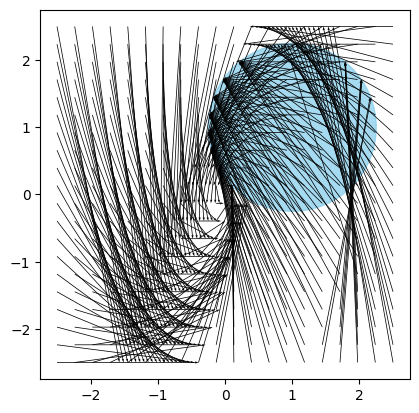

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.quiver(
    states[:, 0],
    states[:, 1],
    difference[:, 0],
    difference[:, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="black",
    width=0.002,
)
plt.show()

In [5]:
from hcnn.optimization.problem_policy_deviation import ProblemPolicyDeviation
from hcnn.optimization.solver_linearize import SolverLinearize

problem = ProblemPolicyDeviation.factory(
    system=system,
    policy=policy,
    constraint=constraint,
    horizon=15,
    rho=20,
).copy_with(initial_state=jnp.array([1.0, -1.0]))

problem.pretty_print(problem.x0)
print("cost", problem.cost_fun(problem.x0))
# print("lb", jnp.all(problem.lower_bound - 1e-6 <= problem.constraints(problem.x0)))
# print("ub", jnp.all(problem.constraints(problem.x0) <= problem.upper_bound + 1e-6))

actions [[-1.3680273e+00]
 [ 3.7228137e-01]
 [ 4.7636300e-01]
 [ 9.5573477e-02]
 [-7.8078195e-02]
 [-5.3579271e-02]
 [-1.9835520e-03]
 [ 1.2199394e-02]
 [ 5.2362108e-03]
 [-9.1239013e-04]
 [-1.6234950e-03]
 [-4.1201263e-04]
 [ 2.3245912e-04]
 [ 1.9038154e-04]
 [ 1.7937200e-05]]
policy_actions [[-1.3680273e+00]
 [ 3.7228137e-01]
 [ 4.7636300e-01]
 [ 9.5573477e-02]
 [-7.8078195e-02]
 [-5.3579271e-02]
 [-1.9835520e-03]
 [ 1.2199394e-02]
 [ 5.2362108e-03]
 [-9.1239013e-04]
 [-1.6234950e-03]
 [-4.1201263e-04]
 [ 2.3245912e-04]
 [ 1.9038154e-04]
 [ 1.7937200e-05]]
states [[ 1.0000000e+00 -1.0000000e+00]
 [ 6.3197267e-01  1.0000000e+00]
 [ 4.2540431e-03  6.3197267e-01]
 [-1.5135562e-01  4.2540431e-03]
 [-6.0036190e-02 -1.5135562e-01]
 [ 1.3241239e-02 -6.0036190e-02]
 [ 1.9698158e-02  1.3241239e-02]
 [ 4.4733668e-03  1.9698158e-02]
 [-3.0253967e-03  4.4733668e-03]
 [-2.2625527e-03 -3.0253967e-03]
 [-1.4954613e-04 -2.2625527e-03]
 [ 4.8951153e-04 -1.4954613e-04]
 [ 2.2704503e-04  4.8951153e-04]

In [6]:
x_star = SolverLinearize.solve(problem)
problem.pretty_print(x_star)
print("cost", problem.cost_fun(x_star))

actions [[-2.2504473e+00]
 [ 9.1068751e-01]
 [ 1.7521111e-02]
 [-2.1366054e-01]
 [-8.7537579e-02]
 [ 1.7604019e-02]
 [ 2.8057724e-02]
 [ 6.6758650e-03]
 [-4.1912296e-03]
 [-3.2495128e-03]
 [-2.5234761e-04]
 [ 6.8876462e-04]
 [ 3.2964299e-04]
 [-3.8493308e-05]
 [-9.4908341e-05]]
policy_actions [[-1.3680532e+00]
 [ 9.1068578e-01]
 [ 1.7520986e-02]
 [-2.1366139e-01]
 [-8.7537237e-02]
 [ 1.7604541e-02]
 [ 2.8057629e-02]
 [ 6.6762464e-03]
 [-4.1912622e-03]
 [-3.2495689e-03]
 [-2.5246420e-04]
 [ 6.8871165e-04]
 [ 3.2963228e-04]
 [-3.8390033e-05]
 [-9.4787225e-05]]
states [[ 9.9998790e-01 -1.0000563e+00]
 [-2.5041357e-01  1.0000000e+00]
 [-3.3974722e-01 -2.5040591e-01]
 [-7.1821295e-02 -3.3974296e-01]
 [ 5.4264110e-02 -7.1820103e-02]
 [ 3.8543027e-02  5.4260645e-02]
 [ 1.8876219e-03  3.8542744e-02]
 [-8.5970992e-03  1.8881940e-03]
 [-3.8092025e-03 -8.5965814e-03]
 [ 5.9667497e-04 -3.8086239e-03]
 [ 1.1545457e-03  5.9616828e-04]
 [ 3.0653112e-04  1.1547819e-03]
 [-1.6003159e-04  3.0621115e-04]

cost 0.38930959
lb True
ub True


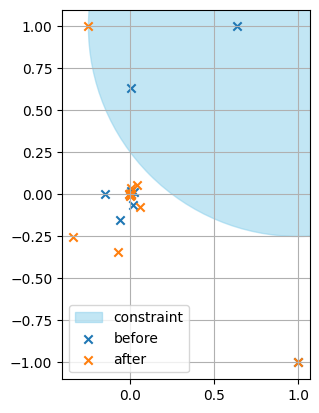

In [7]:
print("cost", problem.cost_fun(x_star))
print("lb", jnp.all(problem.lower_bound - 1e-2 <= problem.constraints(x_star)))
print("ub", jnp.all(problem.constraints(x_star) <= problem.upper_bound + 1e-2))


optvar_star = problem.debug_optvar(x_star)
optvar_0 = problem.debug_optvar(problem.x0)

# Create figure and axis
fig, ax = plt.subplots()
circle = plt.Circle(center, radius, color="skyblue", alpha=0.5, label="constraint")
ax.add_artist(circle)
plt.scatter(optvar_0.states[:, 0], optvar_0.states[:, 1], marker="x", label="before")
plt.scatter(optvar_star.states[:, 0], optvar_star.states[:, 1], marker="x", label="after")
ax.set_aspect("equal")
plt.legend()
plt.grid(True)
plt.show()